In [1]:
from paths import path_to_tiles_tensor_3C
from paths import path_to_tiles_metadata_enriched

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

In [3]:
tiles_3c = torch.load(path_to_tiles_tensor_3C)
meta = pd.read_csv(path_to_tiles_metadata_enriched)

In [4]:
retrain_bool = False

if retrain_bool == True:
    device = "cuda" if torch.cuda.is_available() else "cpu"
    BATCH_SIZE = 128
    TILE_SIZE = 336

    model = timm.create_model(
        "vit_small_patch16_224",
        pretrained = False,        # weights come from your checkpoint, no need to download ImageNet
        num_classes = 0,
        img_size = TILE_SIZE).to(device)

    # load weights
    model.load_state_dict(torch.load("models/rnc_vit_s_50_epochs.pt", map_location = device))
    model.eval()
    loader = DataLoader(tiles_3c, batch_size = BATCH_SIZE, shuffle = False)

    embeddings = []
    with torch.inference_mode():
        for xb in loader:
            with torch.autocast(device, dtype = torch.bfloat16, enabled = device == "cuda"):
                z = model(xb.to(device))
            embeddings.append(z.float().cpu())

    embeddings = torch.cat(embeddings)   # (N, 384)
    torch.save(embeddings, "embeddings/vit_embeddings_RnC.pt")

else:
    embeddings = torch.load("embeddings/vit_embeddings_RnC.pt")

In [ ]:
xy = TSNE(
    n_components = 2,
    perplexity = 20,        
    metric = "cosine",
    init = "pca",
    learning_rate = "auto",
    random_state = 42,
).fit_transform(embeddings)

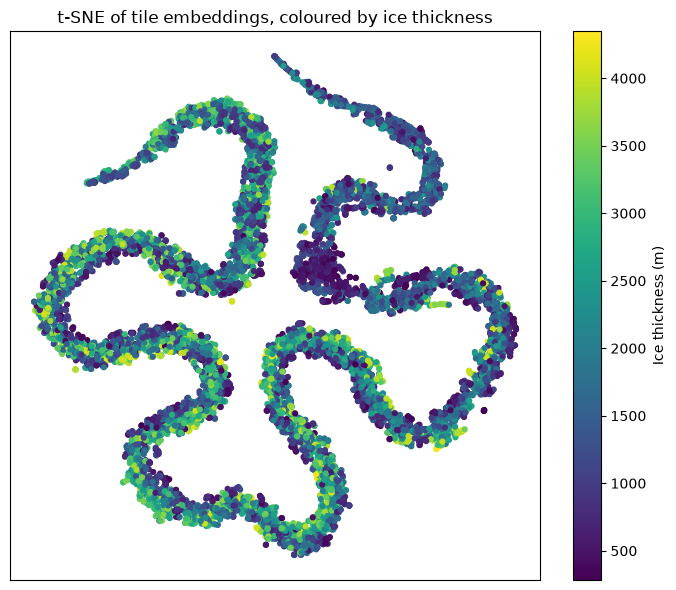

In [6]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["ice_thickness"], cmap = "viridis", s = 12)
fig.colorbar(sc, ax = ax, label = "Ice thickness (m)")
ax.set_title("t-SNE of tile embeddings, coloured by ice thickness")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In [7]:
meta

,Unnamed: 0,granule_id,flight,x_center_idx,y_center_idx,tile_id,X,Y,LON,LAT,...,tile_vertical_span_m,bed_std_m,peak_bed_echo_db,campaign,survey,pmp,VY,VX,ice_speed,basal_friction_beta
0,0,ER2HI1B_2017023_ICP8_JKB2r_F07T02a_000,ICP8/F07,168,1054,ER2HI1B_2017023_ICP8_JKB2r_F07T02a_000_0168,2.233971e+06,-1.003400e+06,114.187485,-67.733750,...,-567.550895,45.556204,196.545,ICP8,ER2HI,-0.996706,-96.193986,207.605167,228.808191,-3.190327
1,1,ER2HI1B_2017023_ICP8_JKB2r_F07T03a_000,ICP8/F07,840,1022,ER2HI1B_2017023_ICP8_JKB2r_F07T03a_000_0840,2.300701e+06,-8.993874e+05,111.351460,-67.544975,...,-567.550741,41.048903,186.433,ICP8,ER2HI,-1.045531,-50.353495,42.073722,65.617624,-2.693011
2,2,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,168,1111,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0168,2.311783e+06,-9.074552e+05,111.431730,-67.427400,...,-567.550741,134.157683,178.590,ICP8,ER2HI,-1.106185,-43.294080,86.659491,96.872312,-2.829029
3,3,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,504,1021,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0504,2.309200e+06,-9.009693e+05,111.313995,-67.469670,...,-567.550972,95.571549,199.023,ICP8,ER2HI,-0.984125,-47.504314,49.664304,68.725563,-2.684812
4,4,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000,ICP8/F07,840,1038,ER2HI1B_2017023_ICP8_JKB2r_F07T05a_000_0840,2.303299e+06,-9.004596e+05,111.352684,-67.520050,...,-567.550972,65.878738,183.386,ICP8,ER2HI,-1.049232,-53.599622,37.984723,65.694434,-2.686695
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10810,10810,IR2HI1B_2012346_WSB_JKB2h_R40b_010,ICP5/F18,504,1633,IR2HI1B_2012346_WSB_JKB2h_R40b_010_0504,5.253390e+05,-1.209101e+06,156.515850,-77.910126,...,-567.550741,122.428389,167.868,ICP5,IR2HI,-1.545555,1.842489,-4.050475,4.449844,-1.917381
10811,10811,IR2HI1B_2012346_WSB_JKB2h_R40b_010,ICP5/F18,840,1178,IR2HI1B_2012346_WSB_JKB2h_R40b_010_0840,5.180543e+05,-1.211759e+06,156.852360,-77.914154,...,-567.550741,234.919537,185.486,ICP5,IR2HI,-0.865722,1.845658,-3.333031,3.809928,-1.846310
10812,10812,IR2HI1B_2012346_WSB_JKB2h_R40b_010,ICP5/F18,1176,1643,IR2HI1B_2012346_WSB_JKB2h_R40b_010_1176,5.107318e+05,-1.214441e+06,157.191020,-77.917700,...,-567.550741,242.606880,149.676,ICP5,IR2HI,-1.563717,0.103418,-1.201265,1.205708,-1.817687
10813,10813,IR2HI1B_2012346_WSB_JKB2h_R40b_010,ICP5/F18,1512,1134,IR2HI1B_2012346_WSB_JKB2h_R40b_010_1512,5.033827e+05,-1.217118e+06,157.530870,-77.920960,...,-567.550895,264.692946,198.221,ICP5,IR2HI,-0.848514,-1.127794,0.353135,1.181789,-1.846676


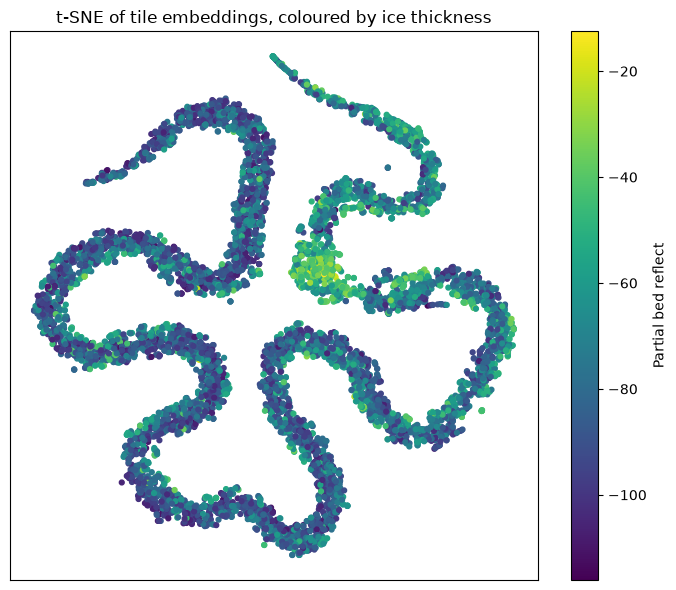

In [9]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["partial_bed_reflect"], cmap = "viridis", s = 12)
fig.colorbar(sc, ax = ax, label = "Partial bed reflect")
ax.set_title("t-SNE of tile embeddings, coloured by ice thickness")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

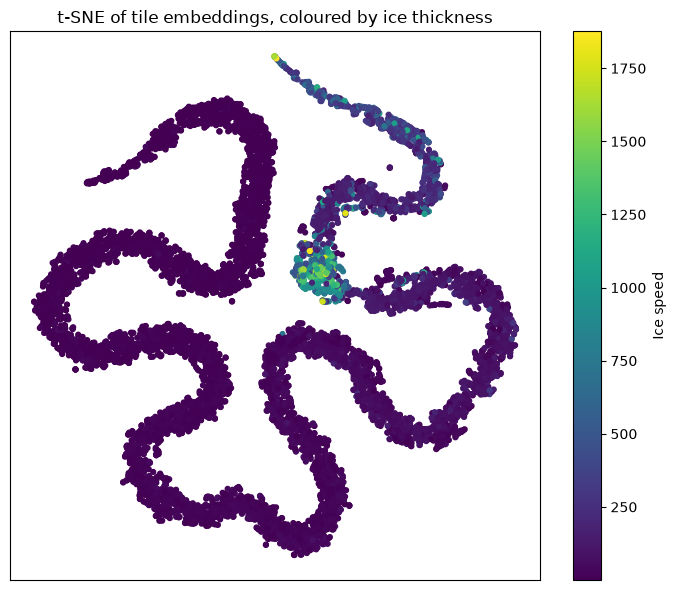

In [11]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["ice_speed"], cmap = "viridis", s = 12)
fig.colorbar(sc, ax = ax, label = "Ice speed")
ax.set_title("t-SNE of tile embeddings, coloured by ice thickness")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

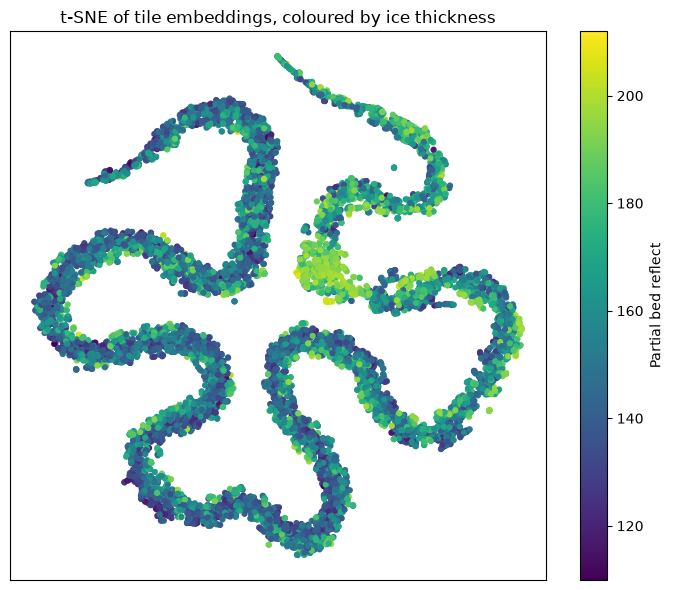

In [13]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["peak_bed_echo_db"], cmap = "viridis", s = 12)
fig.colorbar(sc, ax = ax, label = "Partial bed reflect")
ax.set_title("t-SNE of tile embeddings, coloured by ice thickness")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

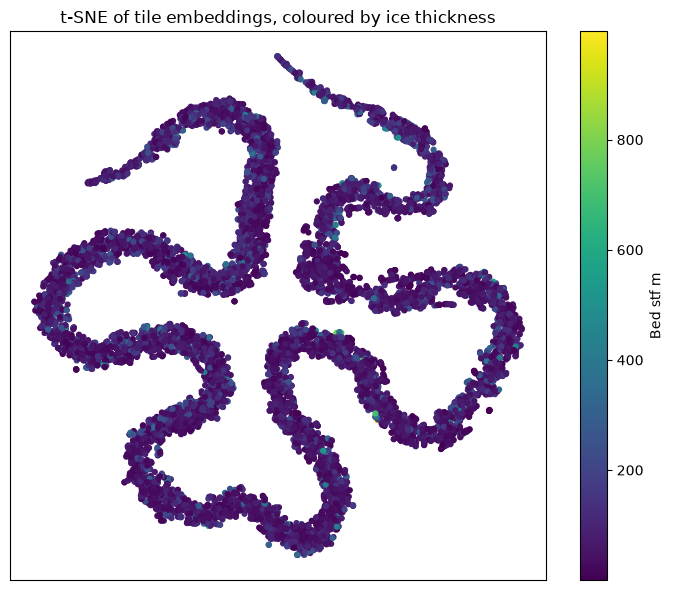

In [15]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["bed_std_m"], cmap = "viridis", s = 12)
fig.colorbar(sc, ax = ax, label = "Bed stf m")
ax.set_title("t-SNE of tile embeddings, coloured by ice thickness")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from scipy.stats import spearmanr

Z = embeddings.numpy() if hasattr(embeddings, "numpy") else embeddings   # (N, 384)
y = meta["bed_std_m"].to_numpy()

# Pearson, vectorised
Zc = (Z - Z.mean(0)) / Z.std(0)
yc = (y - y.mean()) / y.std()
r = Zc.T @ yc / len(y)                      # (384,)

top = np.argsort(-np.abs(r))[:10]
for i in top:
    print(f"dim {i:3d}  r = {r[i]:+.3f}")

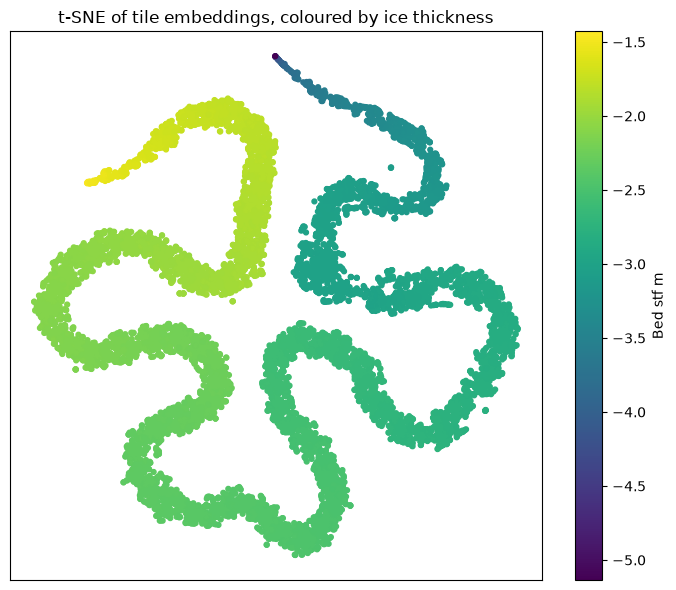

In [16]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["basal_friction_beta"], cmap = "viridis", s = 12)
fig.colorbar(sc, ax = ax, label = "Bed stf m")
ax.set_title("t-SNE of tile embeddings, coloured by ice thickness")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

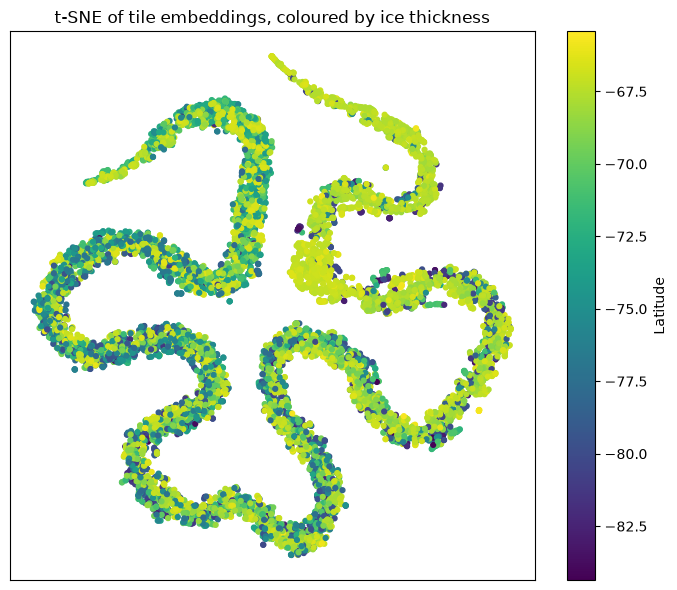

In [18]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["LAT"], cmap = "viridis", s = 12)
fig.colorbar(sc, ax = ax, label = "Latitude")
ax.set_title("t-SNE of tile embeddings, coloured by ice thickness")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In [21]:
embeddings.std(dim = 0).sum()

tensor(440.2695)

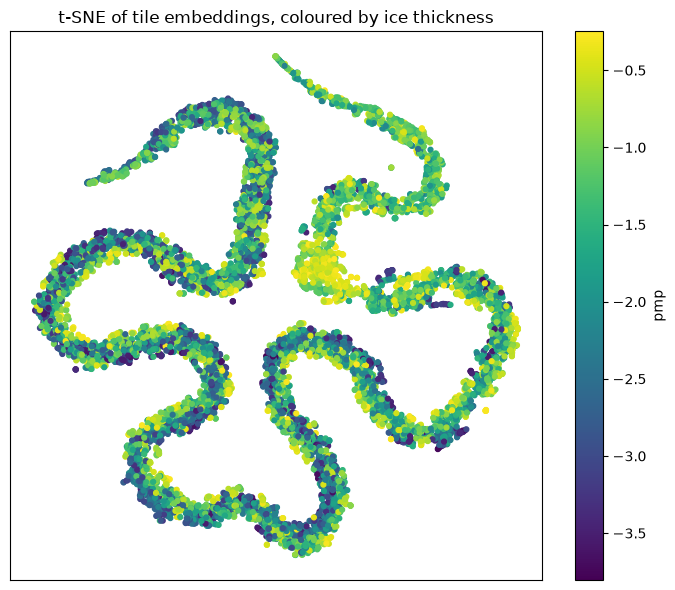

In [23]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["pmp"], cmap = "viridis", s = 12)
fig.colorbar(sc, ax = ax, label = "pmp")
ax.set_title("t-SNE of tile embeddings, coloured by ice thickness")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

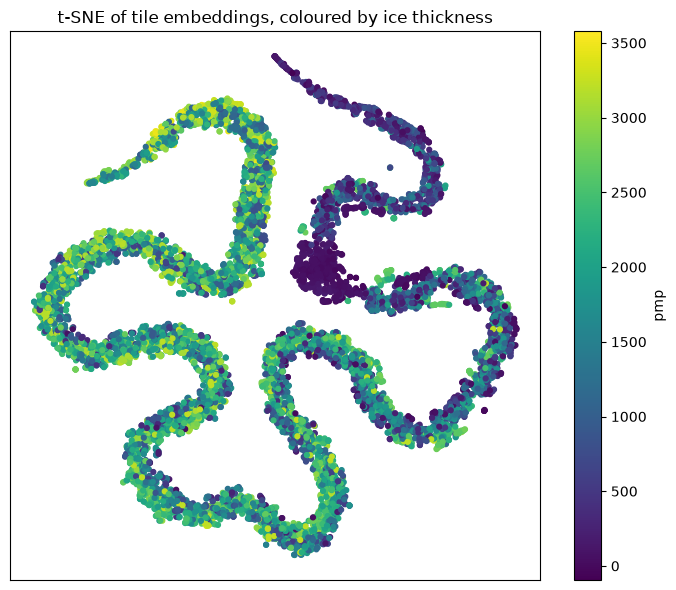

In [24]:
fig, ax = plt.subplots(figsize = (7, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c = meta["surface_elevation"], cmap = "viridis", s = 12)
fig.colorbar(sc, ax = ax, label = "pmp")
ax.set_title("t-SNE of tile embeddings, coloured by ice thickness")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In [26]:
embeddings.shape

torch.Size([10815, 384])

In [28]:
import numpy as np
from scipy.stats import spearmanr

Z = embeddings.numpy() if hasattr(embeddings, "numpy") else embeddings   # (N, 384)
y = meta["bed_std_m"].to_numpy()

# Pearson, vectorised
Zc = (Z - Z.mean(0)) / Z.std(0)
yc = (y - y.mean()) / y.std()
r = Zc.T @ yc / len(y)                      # (384,)

top = np.argsort(-np.abs(r))[:5]
for i in top:
    print(f"dim {i:3d}  r = {r[i]:+.3f}")

dim 138  r = -0.185
dim 301  r = -0.184
dim 334  r = -0.169
dim 234  r = -0.162
dim 177  r = +0.159


In [29]:
Z = embeddings.numpy() if hasattr(embeddings, "numpy") else embeddings   # (N, 384)
y = meta["ice_thickness"].to_numpy()

# Pearson, vectorised
Zc = (Z - Z.mean(0)) / Z.std(0)
yc = (y - y.mean()) / y.std()
r = Zc.T @ yc / len(y)                      # (384,)

top = np.argsort(-np.abs(r))[:5]
for i in top:
    print(f"dim {i:3d}  r = {r[i]:+.3f}")

dim  90  r = -0.378
dim 380  r = +0.374
dim 276  r = -0.359
dim 249  r = +0.347
dim 128  r = +0.343


In [30]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import numpy as np

Z = embeddings.numpy()                      # (N, 384)
y = meta["bed_std_m"].to_numpy()

Z_tr, Z_te, y_tr, y_te = train_test_split(Z, y, train_size=0.7, random_state=0)

mu, sd = Z_tr.mean(0), Z_tr.std(0)          # standardise using train stats only
model = RidgeCV(alphas=np.logspace(-2, 3, 12)).fit((Z_tr - mu) / sd, y_tr)

pred = model.predict((Z_te - mu) / sd)
print("R²:", r2_score(y_te, pred))

R²: 0.5935486642403217


In [ ]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import numpy as np

Z = embeddings.numpy()                      # (N, 384)
y = meta["surface_elevation"].to_numpy()

Z_tr, Z_te, y_tr, y_te = train_test_split(Z, y, train_size = 0.5, random_state = 0)

mu, sd = Z_tr.mean(0), Z_tr.std(0)          # standardise using train stats only
model = RidgeCV(alphas = np.logspace(-2, 3, 12)).fit((Z_tr - mu) / sd, y_tr)

pred = model.predict((Z_te - mu) / sd)
print("R²:", r2_score(y_te, pred))

R²: 0.8124837980596141


In [39]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import numpy as np

Z = embeddings.numpy()
y = meta["ice_thickness"].to_numpy()

Z_tr, Z_te, y_tr, y_te = train_test_split(Z, y, train_size = 0.5, random_state = 0)

mu, sd = Z_tr.mean(0), Z_tr.std(0)          # standardise using train stats only
model = RidgeCV(alphas = np.logspace(-2, 3, 12)).fit((Z_tr - mu) / sd, y_tr)

pred = model.predict((Z_te - mu) / sd)
print("R²:", r2_score(y_te, pred))

R²: 0.8426374095078615


In [2]:
Z = embeddings.numpy()
y = meta["ice_speed"].to_numpy()

valid = ~np.isnan(y)
print(f"Removed {(~valid).sum()} of {len(y)} samples with NaN ({(~valid).mean():.1%})")
Z, y = Z[valid], y[valid]

Z_tr, Z_te, y_tr, y_te = train_test_split(Z, y, train_size = 0.7, random_state=0)

mu, sd = Z_tr.mean(0), Z_tr.std(0)
model = RidgeCV(alphas = np.logspace(-2, 3, 12)).fit((Z_tr - mu) / sd, y_tr)

pred = model.predict((Z_te - mu) / sd)
print("R²:", r2_score(y_te, pred))

NameError: name 'embeddings' is not defined